In [37]:
import g3lhalo
import pyccl as ccl
import matplotlib.pyplot as plt
import numpy as np

In [38]:
# Cosmology
cosmo = {
    'Om_c': 0.28,
    'Om_b': 0.05,
    'h': 0.67,
    'sigma_8': 0.8,
    'n_s': 0.96
}

# Halo mass function
hmf=ccl.halos.MassFuncSheth99()

# Halo bias
hbf=ccl.halos.HaloBiasSheth01()

# Concentration mass Relation
cmfunc=ccl.halos.ConcentrationDuffy08()


# HOD
# HOD parameters
alpha=1
sigma=0.2
Mth=1e12
Mprime=20*Mth
beta=1

# Correlation between galaxy populations
A=0 # 0 ==> No correlation between populations
epsilon=0

# Scaling of halo profile concentration
flens=1 # 1 ==> Same as dark matter

# Get HOD
hod_cen, hod_sat = g3lhalo.HOD_Zheng(alpha, Mth, sigma, Mprime, beta)

# Define model
model = g3lhalo.halomodel(verbose=True, cosmo=cosmo, hmfunc=hmf, hbfunc=hbf, cmfunc=cmfunc)
model.set_hods(hod_cen, hod_sat, A=A, epsilon=epsilon, flens1=flens, flens2=flens)

Setting cosmology
Om_c: 0.28
Om_b: 0.05
h: 0.67
sigma_8: 0.8
n_s: 0.96
Also setting linear matter power spectrum
Setting halo mass function
Setting halo bias function
Setting concentration mass relation


In [39]:
import glob, os, re

TOMO_DIR = '/home/rhoffmann/MA/Tomobins'

# n(z) aus den gespeicherten Tomobin-Dateien einlesen (z, n(z))
sources = {}   # key: Quell-TOMOBIN (int)
for f in sorted(glob.glob(os.path.join(TOMO_DIR, 'KiDS', 'source_bin*_nz.ascii'))):
    k = int(re.search(r'source_bin(\d+)_nz', f).group(1))
    sources[k] = np.loadtxt(f, unpack=True)

lenses = {}    # key: Lens-Name, z.B. 'BGS_0.1-0.2'
for f in glob.glob(os.path.join(TOMO_DIR, 'DESI', '*_nz.ascii')):
    name = os.path.basename(f).replace('_nz.ascii', '')
    lenses[name] = np.loadtxt(f, unpack=True)

# Lenses nach mittlerer Rotverschiebung sortieren
lenses = dict(sorted(lenses.items(), key=lambda kv: np.trapezoid(kv[1][0]*kv[1][1], kv[1][0])))

# Gemeinsames z-Gitter, n(z) interpolieren und normieren
zs = np.linspace(0, 2, 2001)

def on_grid(z, n):
    n = np.interp(zs, z, n, left=0, right=0)
    return n/np.trapezoid(n, zs)

n_sources = {k: on_grid(*v) for k, v in sources.items()}
n_lenses = {k: on_grid(*v) for k, v in lenses.items()}

print('Lenses :', list(n_lenses))
print('Sources:', list(n_sources))

Lenses : ['BGS_0.1-0.2', 'BGS_0.2-0.3', 'BGS_0.3-0.4', 'LRG_0.4-0.6', 'LRG_0.6-0.8']
Sources: [1, 2, 3, 4, 5, 6]


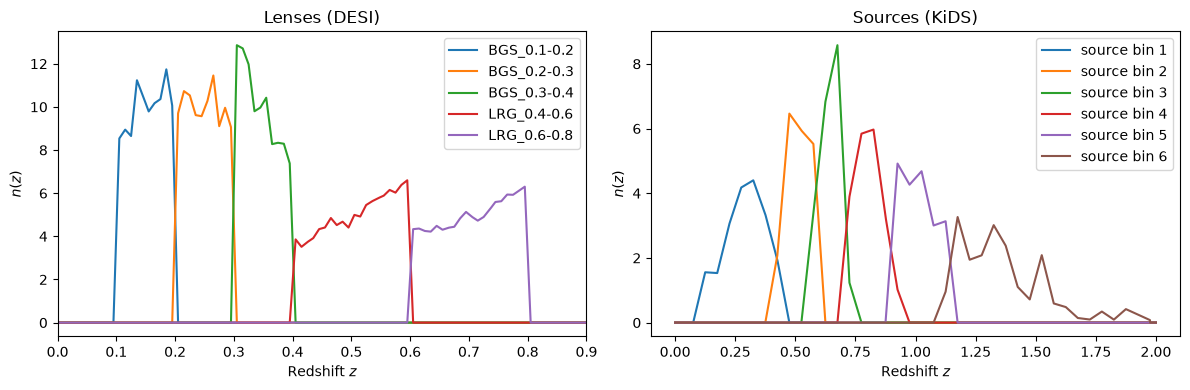

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, n in n_lenses.items():
    axes[0].plot(zs, n, label=name)
for k, n in n_sources.items():
    axes[1].plot(zs, n, label=f'source bin {k}')

axes[0].set_xlim(0, 0.9)
axes[0].set_title('Lenses (DESI)')
axes[1].set_title('Sources (KiDS)')
for ax in axes:
    ax.set_xlabel(r'Redshift $z$')
    ax.set_ylabel(r'$n(z)$')
    ax.legend()
plt.tight_layout()
plt.show()

In [41]:
# Nur Kombinationen, bei denen die Quellen hinter der Lens liegen
# (Anteil der Quellen hinter der medianen Lens-Rotverschiebung >= MIN_FRAC)
MIN_FRAC = 0.92

def median_z(n):
    c = np.cumsum(n)
    return zs[np.searchsorted(c, c[-1]/2)]

pairs = []
for lname, nl in n_lenses.items():
    zl = median_z(nl)
    for k, ns in n_sources.items():
        frac = np.trapezoid(ns*(zs > zl), zs)
        if frac >= MIN_FRAC:
            pairs.append((lname, k))

print(len(pairs), 'Lens-Source-Kombinationen:')
for lname, k in pairs:
    print(f'  {lname} x source bin {k}')

22 Lens-Source-Kombinationen:
  BGS_0.1-0.2 x source bin 2
  BGS_0.1-0.2 x source bin 3
  BGS_0.1-0.2 x source bin 4
  BGS_0.1-0.2 x source bin 5
  BGS_0.1-0.2 x source bin 6
  BGS_0.2-0.3 x source bin 2
  BGS_0.2-0.3 x source bin 3
  BGS_0.2-0.3 x source bin 4
  BGS_0.2-0.3 x source bin 5
  BGS_0.2-0.3 x source bin 6
  BGS_0.3-0.4 x source bin 2
  BGS_0.3-0.4 x source bin 3
  BGS_0.3-0.4 x source bin 4
  BGS_0.3-0.4 x source bin 5
  BGS_0.3-0.4 x source bin 6
  LRG_0.4-0.6 x source bin 3
  LRG_0.4-0.6 x source bin 4
  LRG_0.4-0.6 x source bin 5
  LRG_0.4-0.6 x source bin 6
  LRG_0.6-0.8 x source bin 4
  LRG_0.6-0.8 x source bin 5
  LRG_0.6-0.8 x source bin 6


In [42]:
from scipy.special import jv
from scipy.interpolate import CubicSpline
import numpy as np

# Dichtes ell-Gitter
ells_fine = np.geomspace(1e-3, 1e5, 5000)

gamma_t_all = {}

for lname, k in pairs:

    projection.set_nz_lenses(zs, n_lenses[lname])
    projection.set_nz_sources(zs, n_sources[k])

    _, _, C_fine = projection.C_kg(ells_fine, 1)

    # Prüfen, ob C_ell positiv und endlich ist
    if not np.all(np.isfinite(C_fine)):
        raise ValueError(f"Non-finite C_ell: {lname}, source {k}")

    if np.any(C_fine <= 0):
        raise ValueError(f"Non-positive C_ell: {lname}, source {k}")

    # Interpolation
    spline = CubicSpline(
        np.log(ells_fine),
        np.log(C_fine)
    )

    ell_int = np.geomspace(1e-3, 1e5, 10000)

    C_int = np.exp(spline(np.log(ell_int)))

    gamma_t = []

    for th in thetas_rad:

        integrand = (
            ell_int**2
            * C_int
            * jv(2, ell_int * th)
        )

        gt = np.trapezoid(
            integrand,
            x=np.log(ell_int)
        ) / (2 * np.pi)

        gamma_t.append(gt)

    gamma_t_all[(lname, k)] = np.array(gamma_t)

KeyboardInterrupt: 

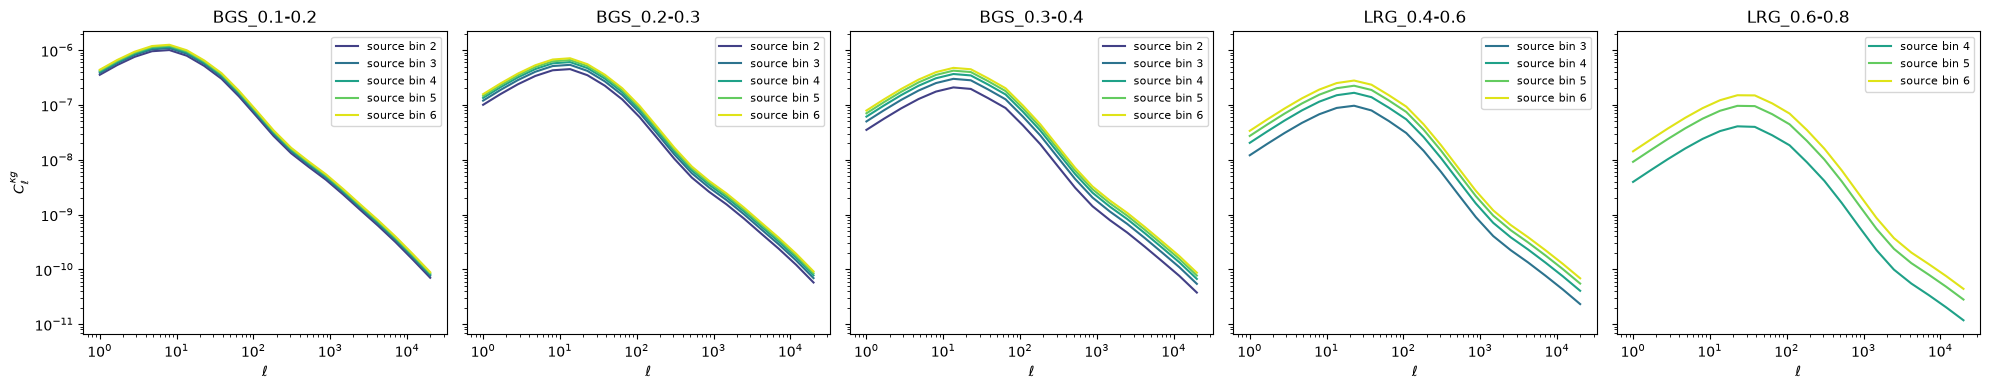

In [ ]:
lens_names = list(n_lenses)
src_keys = list(n_sources)
colors = dict(zip(src_keys, plt.cm.viridis(np.linspace(0, 0.95, len(src_keys)))))

fig, axes = plt.subplots(1, len(lens_names), figsize=(4*len(lens_names), 4), sharey=True)
for ax, lname in zip(np.atleast_1d(axes), lens_names):
    for k in src_keys:
        if (lname, k) in C_kg_all:
            ax.loglog(ells, C_kg_all[(lname, k)], color=colors[k], label=f'source bin {k}')
    ax.set_title(lname)
    ax.set_xlabel(r'$\ell$')
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel(r'$C_\ell^{\kappa g}$')
plt.tight_layout()
plt.show()

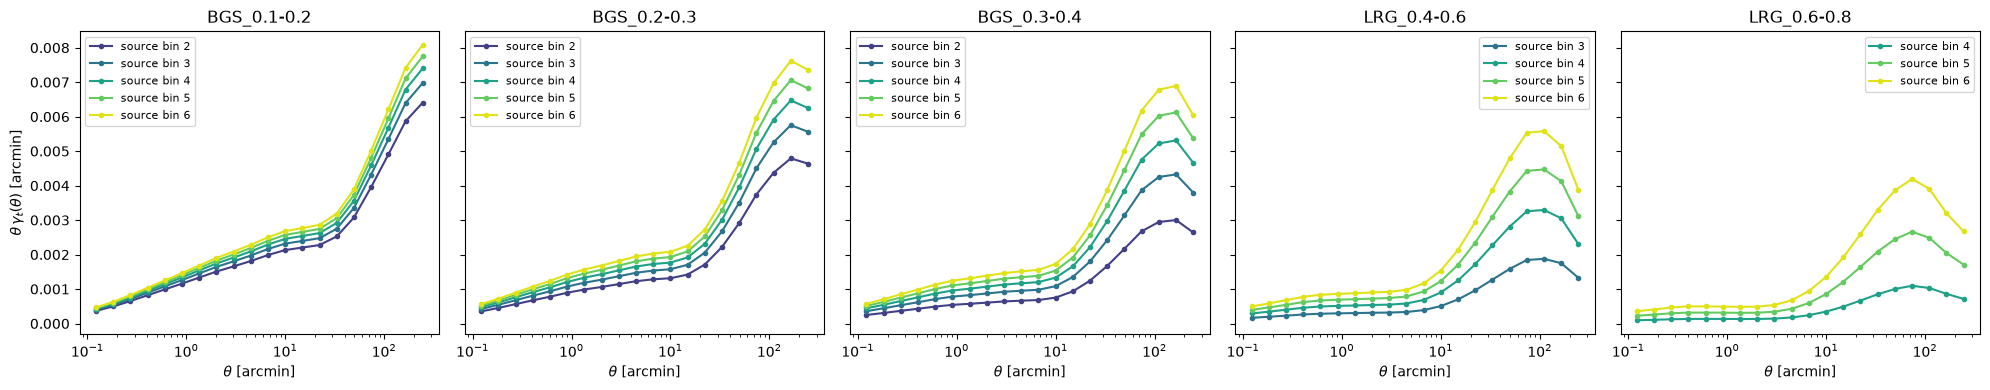

In [ ]:
fig, axes = plt.subplots(1, len(lens_names), figsize=(4*len(lens_names), 4), sharey=True)
for ax, lname in zip(np.atleast_1d(axes), lens_names):
    for k in src_keys:
        if (lname, k) in gamma_t_all:
            ax.semilogx(thetas, gamma_t_all[(lname, k)]*thetas, 'o-', ms=3,
                        color=colors[k], label=f'source bin {k}')
    ax.set_title(lname)
    ax.set_xlabel(r'$\theta$ [arcmin]')
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel(r'$\theta\,\gamma_t(\theta)$ [arcmin]')
plt.tight_layout()
plt.show()